In [1]:
# ============================================================
# Temporal Data Investigation - Imports
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# ============================================================
# Load Temporal Datasets
# ============================================================

VALUATIONS_PATH = '../../../data/raw/player_valuations.csv'
APPEARANCES_PATH = '../../../data/raw/appearances.csv'
GAMES_PATH = '../../../data/raw/games.csv'
PLAYERS_PATH = '../../../data/raw/players.csv'

df_valuations = pd.read_csv(VALUATIONS_PATH)
df_appearances = pd.read_csv(APPEARANCES_PATH)
df_games = pd.read_csv(GAMES_PATH)
df_players = pd.read_csv(PLAYERS_PATH)

print("Datasets loaded successfully.\n")

print(f"Player valuations : {df_valuations.shape}")
print(f"Appearances       : {df_appearances.shape}")
print(f"Games             : {df_games.shape}")
print(f"Players           : {df_players.shape}")

Datasets loaded successfully.

Player valuations : (640176, 6)
Appearances       : (1884051, 13)
Games             : (88665, 23)
Players           : (47669, 26)


In [3]:
# ============================================================
# Inspect Dataset Structures
# ============================================================

datasets = {
    'Player Valuations': df_valuations,
    'Appearances': df_appearances,
    'Games': df_games,
    'Players': df_players
}

for name, data in datasets.items():

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    print(f"Shape: {data.shape}")

    print("\nColumns:")
    print(data.columns.tolist())

    print("\nFirst 3 rows:")
    display(data.head(3))


PLAYER VALUATIONS
Shape: (640176, 6)

Columns:
['player_id', 'date', 'market_value_in_eur', 'current_club_name', 'current_club_id', 'player_club_domestic_competition_id']

First 3 rows:


,player_id,date,market_value_in_eur,current_club_name,current_club_id,player_club_domestic_competition_id
0,405973,2000-01-20,150000,Unknown,3057,BE1
1,342216,2001-07-20,100000,Unknown,1241,SC1
2,3132,2003-12-09,400000,Dynamo Kyiv,126,TR1



APPEARANCES
Shape: (1884051, 13)

Columns:
['appearance_id', 'game_id', 'player_id', 'player_club_id', 'player_current_club_id', 'date', 'player_name', 'competition_id', 'yellow_cards', 'red_cards', 'goals', 'assists', 'minutes_played']

First 3 rows:


,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45



GAMES
Shape: (88665, 23)

Columns:
['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position', 'home_club_manager_name', 'away_club_manager_name', 'stadium', 'attendance', 'referee', 'url', 'home_club_formation', 'away_club_formation', 'home_club_name', 'away_club_name', 'aggregate', 'competition_type']

First 3 rows:


,game_id,competition_id,season,round,date,home_club_id,away_club_id,home_club_goals,away_club_goals,home_club_position,away_club_position,home_club_manager_name,away_club_manager_name,stadium,attendance,referee,url,home_club_formation,away_club_formation,home_club_name,away_club_name,aggregate,competition_type
0,1026846,FIWC,2009,Round of 16,2010-06-26,3449,3589,2,1,NaN,NaN,Óscar Tabárez,Jung-moo Huh,Nelson Mandela Bay Stadium,"30,597.00",Wolfgang Stark,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Uruguay,South Korea,2:1,national_team_competition
1,1026847,FIWC,2009,Round of 16,2010-06-27,3437,6303,3,1,NaN,NaN,Diego Maradona,Javier Aguirre,FNB-Stadium,"84,377.00",Roberto Rosetti,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,Argentina,Mexico,3:1,national_team_competition
2,1027001,FIWC,2009,Round of 16,2010-06-26,3505,3441,1,2,NaN,NaN,Bob Bradley,Milovan Rajevac,Royal Bafokeng Stadium,"34,976.00",Viktor Kassai,https://www.transfermarkt.co.uk/spielbericht/i...,NaN,NaN,United States,Ghana,1:2,national_team_competition



PLAYERS
Shape: (47669, 26)

Columns:
['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur']

First 3 rows:


,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,contract_expiration_date,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,1978-06-09 00:00:00,Centre-Forward,Attack,right,184.00,NaN,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,"1,000,000.00","30,000,000.00"
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,1980-08-06 00:00:00,Goalkeeper,Goalkeeper,left,190.00,NaN,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,"750,000.00","8,000,000.00"
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,1981-01-30 00:00:00,Centre-Forward,Attack,NaN,NaN,NaN,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,"1,000,000.00","34,500,000.00"


In [4]:
# ============================================================
# Convert Date Columns
# ============================================================

df_valuations['date'] = pd.to_datetime(
    df_valuations['date'],
    errors='coerce'
)

df_appearances['date'] = pd.to_datetime(
    df_appearances['date'],
    errors='coerce'
)

df_games['date'] = pd.to_datetime(
    df_games['date'],
    errors='coerce'
)

print("Date columns converted successfully.")

print("\nValuation date range:")
print(
    df_valuations['date'].min(),
    "→",
    df_valuations['date'].max()
)

print("\nAppearance date range:")
print(
    df_appearances['date'].min(),
    "→",
    df_appearances['date'].max()
)

print("\nGame date range:")
print(
    df_games['date'].min(),
    "→",
    df_games['date'].max()
)

Date columns converted successfully.

Valuation date range:
2000-01-20 00:00:00 → 2026-05-18 00:00:00

Appearance date range:
2012-07-03 00:00:00 → 2026-05-18 00:00:00

Game date range:
2006-06-09 00:00:00 → 2026-05-18 00:00:00


In [5]:
# ============================================================
# Investigate Player Valuation History
# ============================================================

valuation_counts = (
    df_valuations
    .groupby('player_id')
    .size()
)

print("=" * 60)
print("PLAYER VALUATION HISTORY")
print("=" * 60)

print(f"Total valuation records : {len(df_valuations):,}")
print(f"Unique players          : {df_valuations['player_id'].nunique():,}")

print("\nValuations per player:")
print(valuation_counts.describe())

print("\nPlayers with at least:")
for n in [2, 5, 10, 20]:
    count = (valuation_counts >= n).sum()

    print(
        f"{n:>2} valuations : "
        f"{count:,} players "
        f"({count / len(valuation_counts) * 100:.1f}%)"
    )

PLAYER VALUATION HISTORY
Total valuation records : 640,176
Unique players          : 41,334

Valuations per player:
count   41,334.00
mean        15.49
std          9.77
min          1.00
25%          8.00
50%         14.00
75%         22.00
max         57.00
dtype: float64

Players with at least:
 2 valuations : 40,016 players (96.8%)
 5 valuations : 35,473 players (85.8%)
10 valuations : 27,981 players (67.7%)
20 valuations : 13,570 players (32.8%)


In [6]:
# ============================================================
# Time Gap Between Consecutive Valuations
# ============================================================

valuation_sorted = (
    df_valuations
    .sort_values(['player_id', 'date'])
    .copy()
)

valuation_sorted['previous_date'] = (
    valuation_sorted
    .groupby('player_id')['date']
    .shift(1)
)

valuation_sorted['gap_days'] = (
    valuation_sorted['date']
    - valuation_sorted['previous_date']
).dt.days

valid_gaps = valuation_sorted['gap_days'].dropna()

print("=" * 60)
print("VALUATION UPDATE INTERVAL")
print("=" * 60)

print(valid_gaps.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
))

print(f"\nMedian gap: {valid_gaps.median():.0f} days")
print(
    f"Approximate months: "
    f"{valid_gaps.median() / 30.44:.1f} months"
)

VALUATION UPDATE INTERVAL
count   598,842.00
mean        185.94
std         147.27
min           1.00
10%          82.00
25%         119.00
50%         168.00
75%         200.00
90%         272.00
max       5,862.00
Name: gap_days, dtype: float64

Median gap: 168 days
Approximate months: 5.5 months


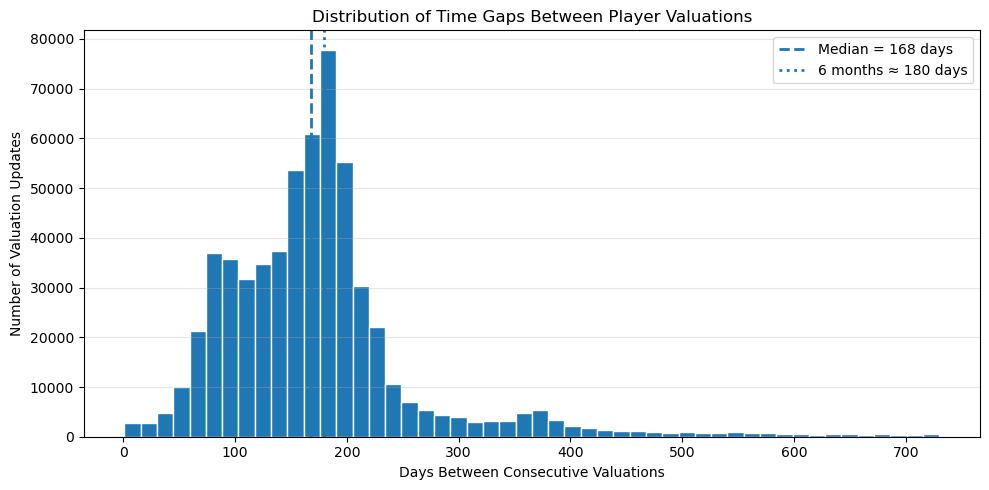

In [7]:
# ============================================================
# Valuation Gap Distribution
# ============================================================

gap_plot = valid_gaps[
    (valid_gaps > 0) &
    (valid_gaps <= 730)
]

plt.figure(figsize=(10, 5))

plt.hist(
    gap_plot,
    bins=50,
    edgecolor='white'
)

plt.axvline(
    valid_gaps.median(),
    linestyle='--',
    linewidth=2,
    label=f'Median = {valid_gaps.median():.0f} days'
)

plt.axvline(
    180,
    linestyle=':',
    linewidth=2,
    label='6 months ≈ 180 days'
)

plt.xlabel('Days Between Consecutive Valuations')
plt.ylabel('Number of Valuation Updates')

plt.title(
    'Distribution of Time Gaps Between Player Valuations'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Player Overlap Between Valuations and Appearances
# ============================================================

valuation_players = set(
    df_valuations['player_id'].dropna().unique()
)

appearance_players = set(
    df_appearances['player_id'].dropna().unique()
)

common_players = valuation_players.intersection(
    appearance_players
)

print("=" * 60)
print("PLAYER OVERLAP ANALYSIS")
print("=" * 60)

print(
    f"Players with valuation data : "
    f"{len(valuation_players):,}"
)

print(
    f"Players with appearance data: "
    f"{len(appearance_players):,}"
)

print(
    f"Players in both datasets    : "
    f"{len(common_players):,}"
)

print(
    f"\nValuation players with appearance history: "
    f"{len(common_players) / len(valuation_players) * 100:.1f}%"
)

# Dataset Intersection

PLAYER OVERLAP ANALYSIS
Players with valuation data : 41,334
Players with appearance data: 28,713
Players in both datasets    : 28,028

Valuation players with appearance history: 67.8%


In [9]:
# ============================================================
# Temporal Overlap - First Appearance Date per Player
# ============================================================

first_appearance = (
    df_appearances
    .groupby('player_id')['date']
    .min()
    .reset_index()
    .rename(
        columns={
            'date': 'first_appearance_date'
        }
    )
)

valuations_with_history = df_valuations.merge(
    first_appearance,
    on='player_id',
    how='inner'
)

valuations_with_history[
    'has_appearance_history'
] = (
    valuations_with_history['date']
    >= valuations_with_history['first_appearance_date']
)

print("=" * 60)
print("TEMPORAL DATA AVAILABILITY")
print("=" * 60)

print(
    f"Valuation records for players with appearances: "
    f"{len(valuations_with_history):,}"
)

print(
    f"Valuations on/after first appearance: "
    f"{valuations_with_history['has_appearance_history'].sum():,}"
)

print(
    f"Valuations before first appearance: "
    f"{(~valuations_with_history['has_appearance_history']).sum():,}"
)

usable_temporal_valuations = (
    valuations_with_history[
        valuations_with_history['has_appearance_history']
    ]
    .copy()
)

print(
    f"\nPotential temporal snapshots: "
    f"{len(usable_temporal_valuations):,}"
)

print(
    f"Players represented: "
    f"{usable_temporal_valuations['player_id'].nunique():,}"
)

TEMPORAL DATA AVAILABILITY
Valuation records for players with appearances: 506,545
Valuations on/after first appearance: 329,104
Valuations before first appearance: 177,441

Potential temporal snapshots: 329,104
Players represented: 27,690


In [10]:
# ============================================================
# Example Player - Valuation Timeline
# ============================================================

eligible_counts = (
    usable_temporal_valuations
    .groupby('player_id')
    .size()
    .sort_values(ascending=False)
)

example_player_id = eligible_counts.index[0]

example_valuations = (
    usable_temporal_valuations[
        usable_temporal_valuations['player_id']
        == example_player_id
    ]
    .sort_values('date')
    [
        [
            'player_id',
            'date',
            'market_value_in_eur',
            'current_club_name'
        ]
    ]
)

print(
    f"Example player ID: {example_player_id}"
)

print(
    f"Number of valuations: "
    f"{len(example_valuations)}"
)

display(example_valuations.head(15))

Example player ID: 179184
Number of valuations: 43


,player_id,date,market_value_in_eur,current_club_name
82483,179184,2013-01-09,2000000,Standard Liège
93635,179184,2013-06-25,3500000,Standard Liège
99049,179184,2013-10-08,5000000,Standard Liège
106225,179184,2014-02-10,8000000,Standard Liège
110580,179184,2014-06-28,8000000,Standard Liège
115642,179184,2014-08-07,8000000,Olympique Marseille
124576,179184,2015-01-14,7500000,Olympique Marseille
133081,179184,2015-06-06,8000000,Olympique Marseille
142902,179184,2015-09-06,9000000,Olympique Marseille
152313,179184,2016-02-04,14000000,Olympique Marseille


In [11]:
# ============================================================
# Candidate Forecast Horizons
# ============================================================

candidate_horizons = {
    '3_months': 3,
    '6_months': 6,
    '12_months': 12
}

tolerance_days = 30

print("=" * 60)
print("CANDIDATE FORECAST HORIZONS")
print("=" * 60)

for name, months in candidate_horizons.items():

    print(
        f"{name:<10} → "
        f"{months:>2} months "
        f"(±{tolerance_days} days tolerance)"
    )

CANDIDATE FORECAST HORIZONS
3_months   →  3 months (±30 days tolerance)
6_months   →  6 months (±30 days tolerance)
12_months  → 12 months (±30 days tolerance)


In [ ]:
# ============================================================
# Future Valuation Matching Function
# ============================================================

def evaluate_forecast_horizon(
    snapshots,
    valuations,
    horizon_months,
    tolerance_days=30
):
    """
    For each temporal snapshot, find the valuation closest to
    snapshot_date + horizon_months within the tolerance window.

    Returns summary statistics only.
    """

    # Keep only required columns
    snapshot_data = (
        snapshots[
            ['player_id', 'date']
        ]
        .rename(columns={'date': 'snapshot_date'})
        .copy()
    )

    valuation_data = (
        valuations[
            ['player_id', 'date', 'market_value_in_eur']
        ]
        .rename(columns={'date': 'future_date'})
        .copy()
    )

    # Desired future date
    snapshot_data['target_date'] = (
        snapshot_data['snapshot_date']
        + pd.DateOffset(months=horizon_months)
    )

    # Lower and upper acceptable dates
    snapshot_data['window_start'] = (
        snapshot_data['target_date']
        - pd.Timedelta(days=tolerance_days)
    )

    snapshot_data['window_end'] = (
        snapshot_data['target_date']
        + pd.Timedelta(days=tolerance_days)
    )

    # Merge by player_id to generate candidate future valuations
    candidates = snapshot_data.merge(
        valuation_data,
        on='player_id',
        how='left'
    )

    # Keep valuations inside target window
    candidates = candidates[
        (candidates['future_date'] >= candidates['window_start']) &
        (candidates['future_date'] <= candidates['window_end']) &
        (candidates['future_date'] > candidates['snapshot_date'])
    ].copy()

    # Distance from ideal target date
    candidates['target_distance_days'] = (
        candidates['future_date']
        - candidates['target_date']
    ).abs().dt.days

    # If multiple valuations exist in the window,
    # choose the one closest to the ideal target date
    candidates = (
        candidates
        .sort_values(
            [
                'player_id',
                'snapshot_date',
                'target_distance_days'
            ]
        )
        .drop_duplicates(
            subset=['player_id', 'snapshot_date'],
            keep='first'
        )
    )

    total_snapshots = len(snapshot_data)
    matched_snapshots = len(candidates)

    coverage = (
        matched_snapshots / total_snapshots * 100
        if total_snapshots > 0
        else 0
    )

    return {
        'Horizon_Months': horizon_months,
        'Tolerance_Days': tolerance_days,
        'Total_Snapshots': total_snapshots,
        'Matched_Snapshots': matched_snapshots,
        'Players': candidates['player_id'].nunique(),
        'Coverage_Percent': coverage,
        'Median_Target_Distance_Days':
            candidates['target_distance_days'].median()
    }


print("Future valuation matching function created.")